# **Traing Data**

In [2]:
import pandas as pd

data = pd.read_csv("/content/Lower_Data.csv")

data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
print(data)

     gender race/ethnicity parental level of education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
0                      none          72             72         

In [4]:
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
# Total number of rows and columns
print(data.shape)

# Column names
print(data.columns)

# Data types of each column
print(data.dtypes)

(1000, 8)
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


In [6]:
# Check missing values
print("Missing Values:")
print(data.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(data.duplicated().sum())

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Rows:
0


In [7]:
# Remove duplicate rows
data = data.drop_duplicates()

# Check missing values
print(data.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


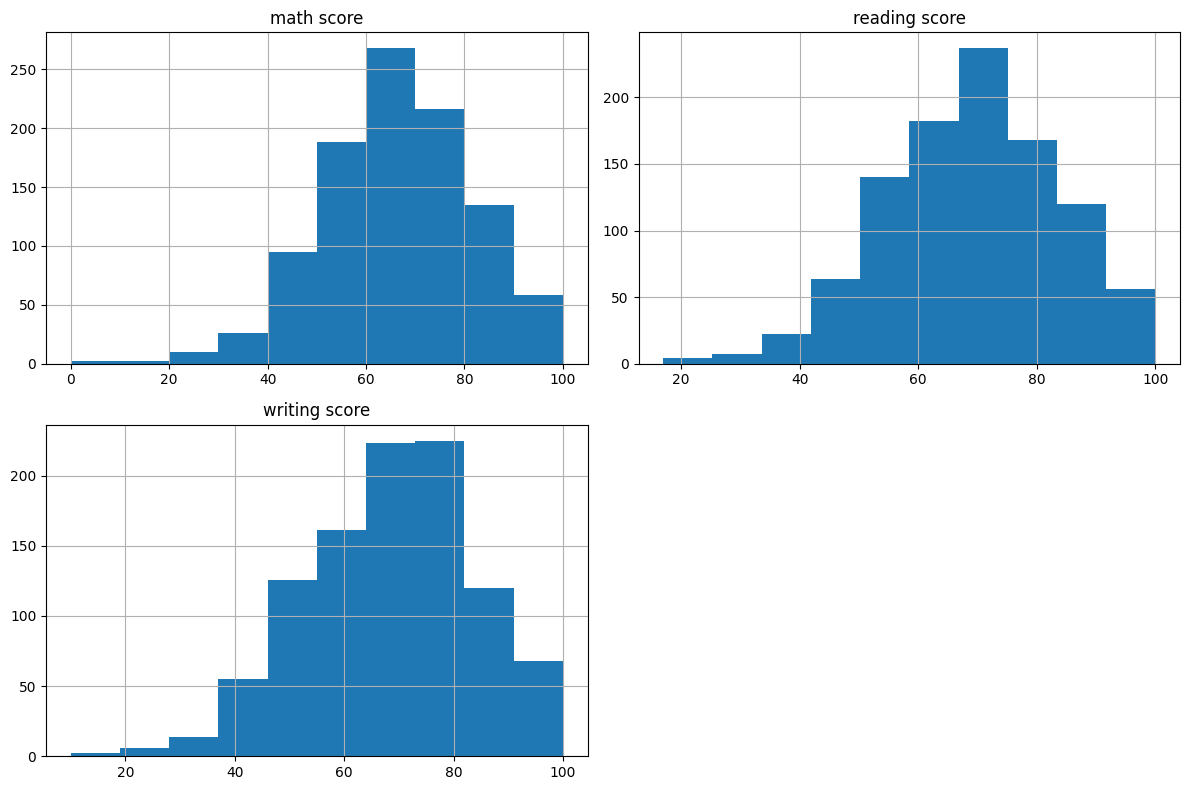

In [10]:
data.hist(figsize=(12, 8))

plt.tight_layout()
plt.show()

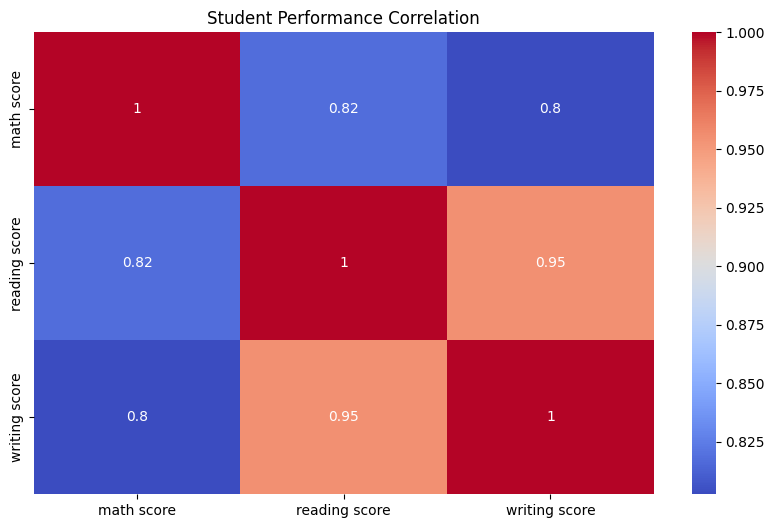

In [11]:
plt.figure(figsize=(10, 6))

sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm')

plt.title("Student Performance Correlation")

plt.show()

In [12]:
print(data.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')


In [13]:
#check data of columns
print(data.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [14]:
# Select input features
X = data.drop('math score', axis=1)

# Select target
y = data['math score']

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  reading score  writing score  
0                    none             72             74  
1               completed             90             88  
2                    none             95             93  
3                    none             57             44  
4                    none             78             75  

Target:
0    72
1    69
2    90
3    47
4    76
Name: math score, dtype: int64


In [15]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 7)
y shape: (1000,)


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (800, 7)
Testing Data: (200, 7)
Training Target: (800,)
Testing Target: (200,)


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns
categorical_columns = X.select_dtypes(include=['object']).columns

# Convert text into numbers
preprocessor = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ],
    remainder='passthrough'
)

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.pipeline import Pipeline

In [21]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [23]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("\nModel:", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("R2 Score:", r2)


Model: Linear Regression
MAE: 4.214763142474854
MSE: 29.095169866715537
R2 Score: 0.8804332983749563

Model: Decision Tree
MAE: 6.24
MSE: 60.52
R2 Score: 0.7512928497927167

Model: Random Forest
MAE: 4.665547023809524
MSE: 36.31139799185091
R2 Score: 0.8507781838302096


In [24]:
#Save the Best Model
import joblib

In [25]:
best_model = trained_models['Linear Regression']

joblib.dump(best_model, 'student_performance_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [26]:
from google.colab import files

files.download('student_performance_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import pandas as pd

new_student = pd.DataFrame([{
    'gender': 'male',
    'race/ethnicity': 'group B',
    'parental level of education': "bachelor's degree",
    'lunch': 'standard',
    'test preparation course': 'completed',
    'reading score': 75,
    'writing score': 80
}])

prediction = best_model.predict(new_student)

print("Predicted Math Score:", prediction[0])

Predicted Math Score: 80.93841010320236


In [28]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("5-Fold Cross-Validation is ready!")

5-Fold Cross-Validation is ready!


In [29]:
for name, model in trained_models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring='r2'
    )

    print("\nModel:", name)
    print("Fold Scores:", scores)
    print("Average R2 Score:", scores.mean())


Model: Linear Regression
Fold Scores: [0.8804333  0.86165874 0.8810633  0.85567747 0.87963568]
Average R2 Score: 0.8716936957022423

Model: Decision Tree
Fold Scores: [0.75129285 0.71205861 0.7433611  0.67889985 0.74149274]
Average R2 Score: 0.7254210308890098

Model: Random Forest
Fold Scores: [0.84848314 0.82878241 0.8437045  0.82461558 0.83883818]
Average R2 Score: 0.8368847609409542


In [30]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

new_models = {
    "Ridge Regression": Ridge(),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

for name, model in new_models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring='r2'
    )

    print("\nModel:", name)
    print("Fold Scores:", scores)
    print("Average R2 Score:", scores.mean())


Model: Ridge Regression
Fold Scores: [0.88046509 0.86155201 0.88122511 0.85576    0.87959359]
Average R2 Score: 0.8717191599998667

Model: Gradient Boosting
Fold Scores: [0.87234182 0.84784437 0.86234971 0.85117483 0.85761195]
Average R2 Score: 0.8582645359220562


In [31]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

model = ExtraTreesRegressor(random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring='r2'
)

print("Model: Extra Trees")
print("Fold Scores:", scores)
print("Average R2 Score:", scores.mean())

Model: Extra Trees
Fold Scores: [0.83341383 0.83414461 0.82250376 0.80063097 0.82228115]
Average R2 Score: 0.8225948637924716


               Model  R2 Score
0  Linear Regression   0.87169
1   Ridge Regression   0.87172
2      Decision Tree   0.72542
3      Random Forest   0.83688
4  Gradient Boosting   0.85826
5        Extra Trees   0.82259


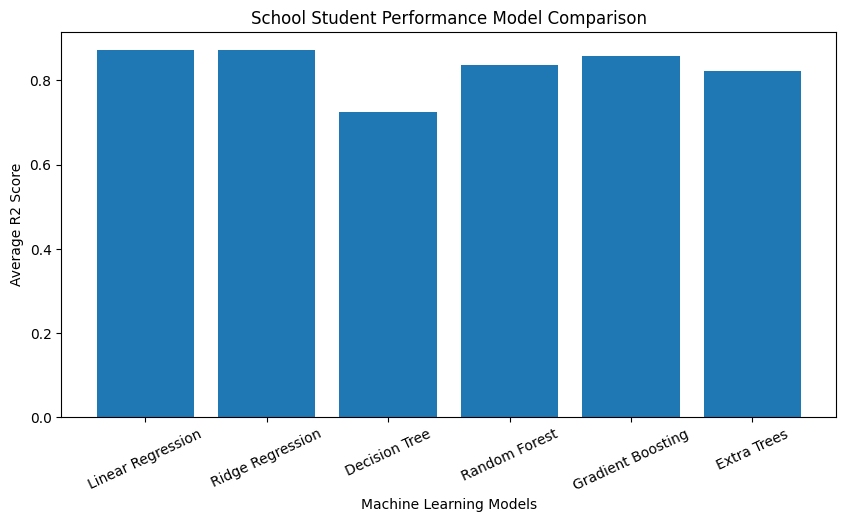

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

results = {
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'Extra Trees'
    ],
    'R2 Score': [
        0.87169,
        0.87172,
        0.72542,
        0.83688,
        0.85826,
        0.82259
    ]
}

results_df = pd.DataFrame(results)

print(results_df)

plt.figure(figsize=(10, 5))

plt.bar(results_df['Model'], results_df['R2 Score'])

plt.xlabel("Machine Learning Models")
plt.ylabel("Average R2 Score")
plt.title("School Student Performance Model Comparison")

plt.xticks(rotation=25)
plt.show()

In [33]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Ridge Regression pipeline
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

# Train Ridge Regression
ridge_model.fit(X_train, y_train)

# Get predictions
ridge_predictions = ridge_model.predict(X_test)

# Compare both models
models_to_compare = {
    "Linear Regression": trained_models['Linear Regression'],
    "Ridge Regression": ridge_model
}

for name, model in models_to_compare.items():

    predictions = model.predict(X_test)

    print("\nModel:", name)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("MSE:", mean_squared_error(y_test, predictions))
    print("R2 Score:", r2_score(y_test, predictions))


Model: Linear Regression
MAE: 4.214763142474854
MSE: 29.095169866715537
R2 Score: 0.8804332983749563

Model: Ridge Regression
MAE: 4.2128411000147805
MSE: 29.087433472118036
R2 Score: 0.8804650911154259


In [34]:
import joblib

best_model = ridge_model

joblib.dump(best_model, 'student_performance_model.pkl')

print("Ridge Regression model saved successfully!")

Ridge Regression model saved successfully!


In [35]:
import joblib

# Load the saved model
loaded_model = joblib.load('student_performance_model.pkl')

# Make predictions
predictions = loaded_model.predict(X_test)

print("Model loaded successfully!")
print("Predicted Scores:", predictions[:10])
print("Actual Scores:", y_test.values[:10])

Model loaded successfully!
Predicted Scores: [76.39899935 58.89937437 76.98418199 76.82543348 87.58125216 78.98606151
 64.66504896 53.03086071 74.15967126 49.23325815]
Actual Scores: [91 53 80 74 84 81 69 54 87 51]
